In [1]:

%cd ..

from pathlib import Path
print(Path.cwd())

import numpy as np
import matplotlib.pyplot as plt

from hardware import ammeter, ammeter_uncertainty, gaussmeter, gaussmeter_uncertainty, horizontal_coils, vertical_coils, modulation_coils, horizontal_coils_uncertainty, vertical_coils_uncertainty, modulation_coils_uncertainty
from scope_header import DSOX1204G, self_test, load_waveforms


plt.rcParams.update({
    "font.sans-serif": ["Cabin", "Libertinus Sans", "DejaVu Sans"],
    "font.serif": ["Libertinus Serif"],
    "font.family": "sans-serif",
    "font.style": "normal",
    "font.weight": "normal",
    "font.size": 14,
    "axes.labelsize": 16,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelweight": "normal",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 14,
    "legend.title_fontsize": 14,
    "figure.titlesize": 18,
    "figure.titleweight": "bold",
    "mathtext.fontset": "cm",
    "mathtext.default": "it",
    "axes.unicode_minus": False,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "legend.edgecolor": "black",
})
%matplotlib inline

from scipy.optimize import curve_fit
from scipy import signal

# scope = DSOX1204G()


c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code
c:\Users\njwan\OneDrive - University of Toronto\Documents\Year 3\3F\PHY327\1 - Optical Pumping in Rubidium\code


# single shot

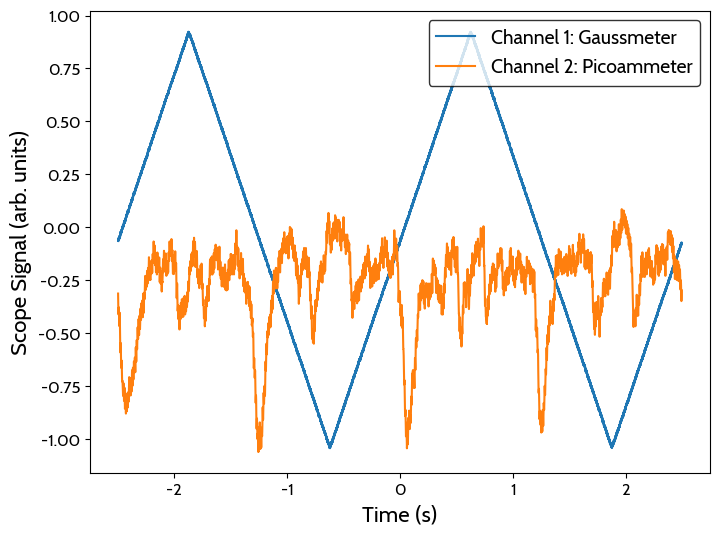

In [2]:
data = load_waveforms("data/24/speed_400_126.npz")
t, V1, V2 = data[1][0], data[1][1], data[2][1]


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()


# manually

In [3]:
# 500 mHz
transmissions = []
for data_num in range(43, 51):
    data = load_waveforms(f"data/24/speed_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 400
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask = (t > 2.5) & (t < 3.5)
    field = gaussmeter(V1[mask]*1e3)
    transmission = ammeter(V2[mask]*1e3)

    transmissions.append(ammeter(V2[mask]*1e3))

transmissions = np.array(transmissions)
average_transmissions = np.mean(transmissions, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field, average_transmissions, label='Average Transmission', color='tab:blue')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')
ax.legend()


FileNotFoundError: [Errno 2] No such file or directory: 'data/24/speed_43.npz'

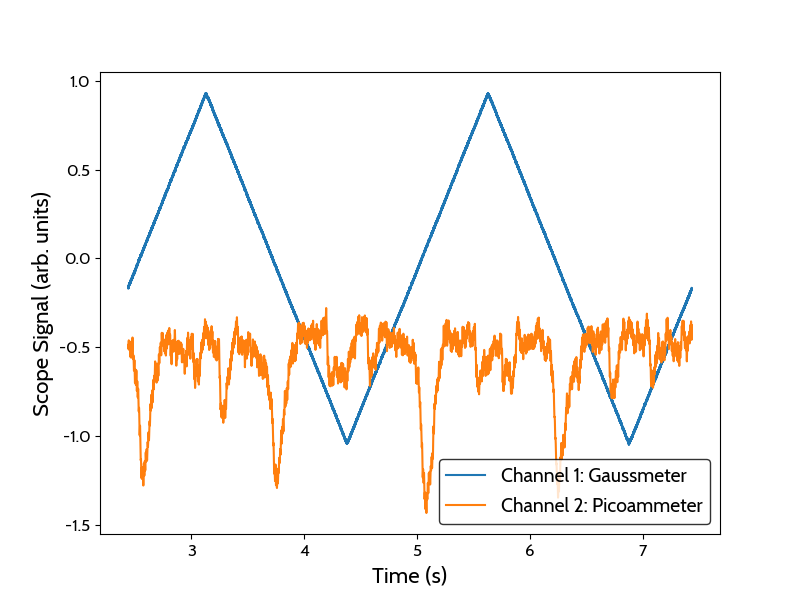

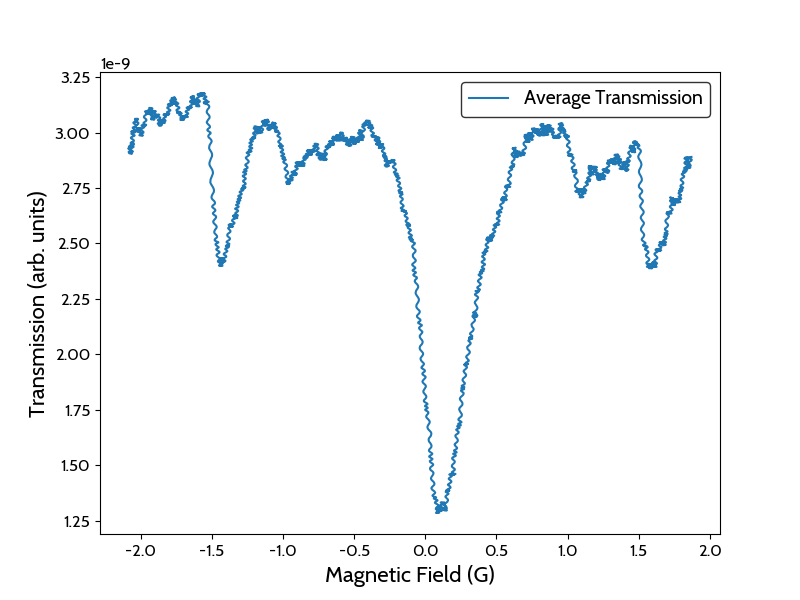

In [ ]:

data = load_waveforms("data/24/speed_51.npz")
t, V1, V2 = data[1][0], data[1][1], data[2][1]


N = 400
t = np.convolve(t, np.ones(N)/N, mode='valid')
V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

fig0, ax0 = plt.subplots(figsize=(8, 6))
ax0.plot(t, V1, label='Channel 1: Gaussmeter', color='tab:blue')
ax0.plot(t, V2*5-2, label='Channel 2: Picoammeter', color='tab:orange')
ax0.set_xlabel('Time (s)')
ax0.set_ylabel('Scope Signal (arb. units)')
ax0.legend()

# 400 mHz

transmissions = []
for data_num in range(51, 59):
    data = load_waveforms(f"data/24/speed_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 400
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask = (t > 4.37) & (t < 5.63)
    field = gaussmeter(V1[mask]*1e3)
    transmission = ammeter(V2[mask]*1e3)

    transmissions.append(ammeter(V2[mask]*1e3))

transmissions = np.array(transmissions)
average_transmissions = np.mean(transmissions, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field, average_transmissions, label='Average Transmission', color='tab:blue')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')
ax.legend()


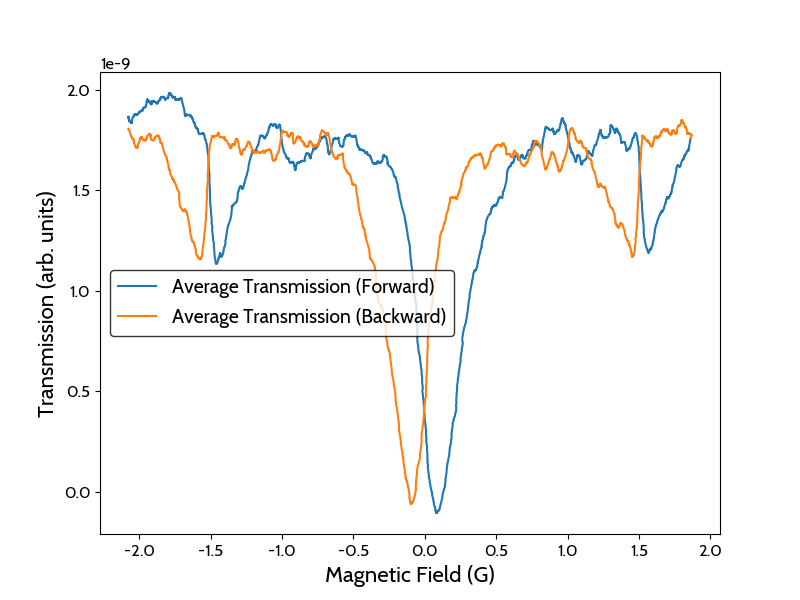

In [ ]:
# 300 mHz
speed = 300 

transmissions_forward = []
transmissions_backward = []
for data_num in range(59, 67):
    data = load_waveforms(f"data/24/speed_{speed}_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 400
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask_forward = (t > -1/(speed*1e-3)/4) & (t < 1/(speed*1e-3)/4)
    mask_backward = (t > 1/(speed*1e-3)/4) & (t < 3/(speed*1e-3)/4)

    field_forward = gaussmeter(V1[mask_forward]*1e3)
    field_backward = gaussmeter(V1[mask_backward]*1e3)

    transmission_forward = ammeter(V2[mask_forward]*1e3)
    transmission_backward = ammeter(V2[mask_backward]*1e3)

    transmissions_forward.append(ammeter(V2[mask_forward]*1e3))
    transmissions_backward.append(ammeter(V2[mask_backward]*1e3))

transmissions_forward = np.array(transmissions_forward)
transmissions_backward = np.array(transmissions_backward)
average_transmissions_forward = np.mean(transmissions_forward, axis=0)
average_transmissions_backward = np.mean(transmissions_backward, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue')
ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')
ax.legend()


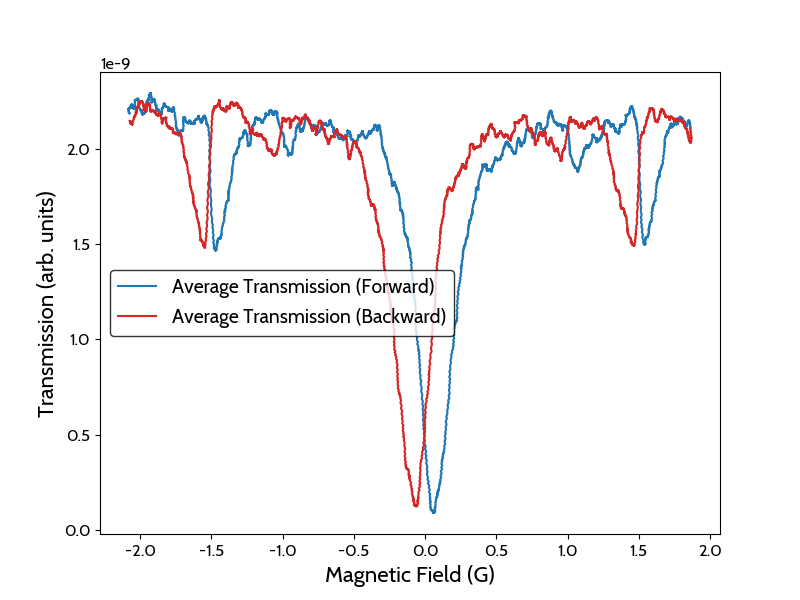

In [ ]:
# 200 mHz
speed = 200 

transmissions_forward = []
transmissions_backward = []
for data_num in range(68, 76):
    data = load_waveforms(f"data/24/speed_{speed}_{data_num}.npz")
    t, V1, V2 = data[1][0], data[1][1], data[2][1]
    N = 400
    t = np.convolve(t, np.ones(N)/N, mode='valid')
    V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
    V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

    mask_forward = (t > -1/(speed*1e-3)/4) & (t < 1/(speed*1e-3)/4)
    mask_backward = (t > 1/(speed*1e-3)/4) & (t < 3/(speed*1e-3)/4)

    field_forward = gaussmeter(V1[mask_forward]*1e3)
    field_backward = gaussmeter(V1[mask_backward]*1e3)

    transmission_forward = ammeter(V2[mask_forward]*1e3)
    transmission_backward = ammeter(V2[mask_backward]*1e3)

    transmissions_forward.append(ammeter(V2[mask_forward]*1e3))
    transmissions_backward.append(ammeter(V2[mask_backward]*1e3))

transmissions_forward = np.array(transmissions_forward)
transmissions_backward = np.array(transmissions_backward)
average_transmissions_forward = np.mean(transmissions_forward, axis=0)
average_transmissions_backward = np.mean(transmissions_backward, axis=0)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue')
ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red')
ax.set_xlabel('Magnetic Field (G)')
ax.set_ylabel('Transmission (arb. units)')
ax.legend()


# automating it

In [ ]:
def lorenzian(x, a, b, c, e):
    return a/(1 + ((x-b)/c)**2) + e

def find_peak_location(x, y, guess, plot = False):
    popt, pcov = curve_fit(lorenzian, x, y, p0=[-1.73e-9, guess, 0.2, 3.5e-9])#, bounds=([-2.5e-9, -np.inf, 0, 2e-9], [-1.5e-9, np.inf, 0.4, 4e-9]))
    b = popt[1]
    b_sigma = np.sqrt(np.diag(pcov))[1]
    print(popt)
    if plot:
        plt.figure(figsize=(8, 6))
        plt.plot(x, y, label='Data', color='tab:blue')
        plt.plot(x, lorenzian(x, *popt), label='Lorenzian Fit', color='tab:red')
        plt.axvline(b, color='tab:green', linestyle='--', label=f'Peak Location: {b:.4f} ± {b_sigma:.4f}')
        plt.xlabel('Magnetic Field (G)')
        plt.ylabel('Transmission (arb. units)')
        plt.legend()
        plt.show()
    return b, b_sigma

def find_peak_location2(x, y, guess, plot = False):
    popt, pcov = curve_fit(lorenzian, x, y, p0=[-0.6e-9, guess, 0.07, 3.5e-9])
    b = popt[1]
    b_sigma = np.sqrt(np.diag(pcov))[1]
    print(popt)
    if plot:
        plt.figure(figsize=(8, 6))
        plt.plot(x, y, label='Data', color='tab:blue')
        plt.plot(x, lorenzian(x, *popt), label='Lorenzian Fit', color='tab:red')
        plt.axvline(b, color='tab:green', linestyle='--', label=f'Peak Location: {b:.4f} ± {b_sigma:.4f}')
        plt.xlabel('Magnetic Field (G)')
        plt.ylabel('Transmission (arb. units)')
        plt.legend()
        plt.show()

    return b, b_sigma

def plot_average(speed, data_range, date, filename):
    transmissions_forward = []
    transmissions_backward = []
    for data_num in data_range:
        data = load_waveforms(f"data/{date}/{filename}_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 800
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -1/(speed*1e-3)/4) & (t < 1/(speed*1e-3)/4)
        mask_backward = (t > 1/(speed*1e-3)/4) & (t < 3/(speed*1e-3)/4)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)
    
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue', marker = '.', markersize = 1)
    ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red', marker = '.', markersize = 1)
    ax.set_xlabel('Magnetic Field (G)')
    ax.set_ylabel('Transmission (arb. units)')
    ax.legend(loc = "upper right")


def speed_test(speed, data_range, plot):
    transmissions_forward = []
    centers_forward = []
    differences_forward = []
    transmissions_backward = []
    centers_backward = []
    differences_backward = []

    for data_num in data_range:
        data = load_waveforms(f"data/24/speed_{speed}_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 800
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -1/(speed*1e-3)/4) & (t < 1/(speed*1e-3)/4)
        mask_backward = (t > 1/(speed*1e-3)/4) & (t < 3/(speed*1e-3)/4)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)

    center_forward_mask = (field_forward > -0.5) & (field_forward < 0.6)
    center_backward_mask = (field_backward > -0.6) & (field_backward < 0.5)
    center_forward, center_forward_sigma = find_peak_location(field_forward[center_forward_mask], average_transmissions_forward[center_forward_mask], 0 + 0.11, False)
    center_backward, center_backward_sigma = find_peak_location(field_backward[center_backward_mask], average_transmissions_backward[center_backward_mask], 0 - 0.11, False)
    
    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue')
        ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red')
        ax.set_xlabel('Magnetic Field (G)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.legend(loc = "upper right")
        
    return center_forward, center_forward_sigma, center_backward, center_backward_sigma

    return 0, 0, 0, 0

def speed_test_sides(speed, data_range, plot):
    transmissions_forward = []
    centers_forward = []
    differences_forward = []
    transmissions_backward = []
    centers_backward = []
    differences_backward = []

    for data_num in data_range:
        data = load_waveforms(f"data/24/speed_{speed}_{data_num}.npz")
        t, V1, V2 = data[1][0], data[1][1], data[2][1]
        N = 800
        t = np.convolve(t, np.ones(N)/N, mode='valid')
        V1 = np.convolve(V1, np.ones(N)/N, mode='valid')
        V2 = np.convolve(V2, np.ones(N)/N, mode='valid')

        mask_forward = (t > -1/(speed*1e-3)/4) & (t < 1/(speed*1e-3)/4)
        mask_backward = (t > 1/(speed*1e-3)/4) & (t < 3/(speed*1e-3)/4)

        field_forward = gaussmeter(V1[mask_forward]*1e3)
        field_backward = gaussmeter(V1[mask_backward]*1e3)

        transmission_forward = ammeter(V2[mask_forward]*1e3)
        transmission_backward = ammeter(V2[mask_backward]*1e3)
        transmissions_forward.append(transmission_forward)
        transmissions_backward.append(transmission_backward)

    transmissions_forward = np.array(transmissions_forward)
    transmissions_backward = np.array(transmissions_backward)
    average_transmissions_forward = np.mean(transmissions_forward, axis=0)
    average_transmissions_backward = np.mean(transmissions_backward, axis=0)


    left_forward_mask = (field_forward > -1.9) & (field_forward < -1)
    left_backward_mask = (field_backward > -2) & (field_backward < -1.1)
    right_forward_mask = (field_forward > 1.1) & (field_forward < 2)
    right_backward_mask = (field_backward > 1) & (field_backward < 1.9)

    left_forward, left_forward_sigma = find_peak_location(field_forward[left_forward_mask], average_transmissions_forward[left_forward_mask], -1.5, plot)
    left_backward, left_backward_sigma = find_peak_location(field_backward[left_backward_mask], average_transmissions_backward[left_backward_mask], -1.5, plot)
    right_forward, right_forward_sigma = find_peak_location(field_forward[right_forward_mask], average_transmissions_forward[right_forward_mask], 1.5, plot)
    right_backward, right_backward_sigma = find_peak_location(field_backward[right_backward_mask], average_transmissions_backward[right_backward_mask], 1.5, plot)



    if plot:
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(field_forward, average_transmissions_forward, label='Average Transmission (Forward)', color='tab:blue')
        ax.plot(field_backward, average_transmissions_backward, label='Average Transmission (Backward)', color='tab:red')
        ax.set_xlabel('Magnetic Field (G)')
        ax.set_ylabel('Transmission (arb. units)')
        ax.legend(loc = "upper right")
        
    return right_forward - left_forward, np.sqrt(left_forward_sigma**2 + right_forward_sigma**2), right_backward - left_backward, np.sqrt(left_backward_sigma**2 + right_backward_sigma**2)

    return 0, 0, 0, 0

[-1.87206137e-09  1.80616343e-01  2.59557333e-01  3.79582736e-09]
[-1.78588731e-09 -1.84904180e-01  2.40012098e-01  3.63225922e-09]
[-1.79947869e-09  1.39155457e-01  2.05915623e-01  3.61462587e-09]
[-1.74437363e-09 -1.37076142e-01  1.98429979e-01  3.60590046e-09]
[-1.99787972e-09  1.12889487e-01  1.79412578e-01  1.89679749e-09]
[-1.87159019e-09 -1.15514756e-01  1.77344588e-01  1.86481742e-09]
[-2.13166265e-09  7.28690085e-02  1.46165595e-01  2.22773416e-09]
[-2.11996713e-09 -8.71498309e-02  1.54663593e-01  2.25279403e-09]
[-2.40338403e-09  3.77981631e-02  1.19383923e-01  3.10595351e-09]
[-2.35415117e-09 -5.00985528e-02  1.22685187e-01  3.10381926e-09]
[-2.20223160e-09  5.18067374e-02  1.32058183e-01  2.56425903e-09]
[-2.23916957e-09 -7.10741926e-02  1.39014800e-01  2.60459877e-09]
[-2.05392663e-09  8.75753386e-02  1.62398137e-01  3.97141455e-09]
[-1.95744734e-09 -1.03630718e-01  1.65629374e-01  3.94882141e-09]


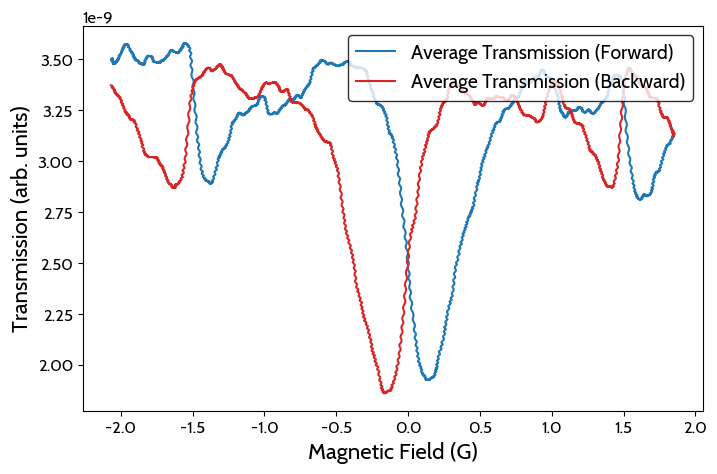

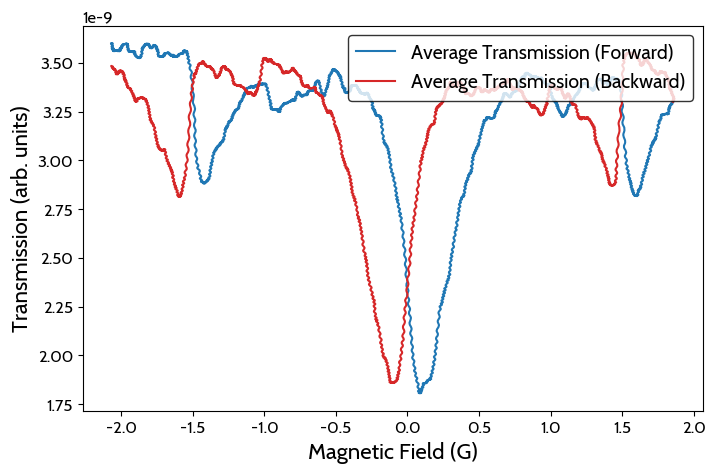

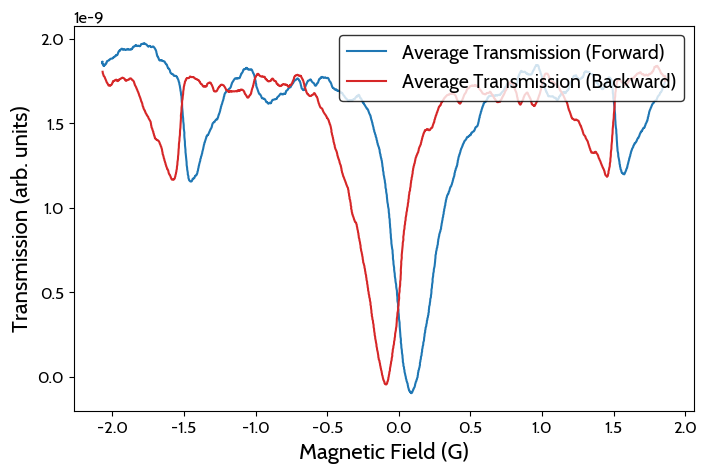

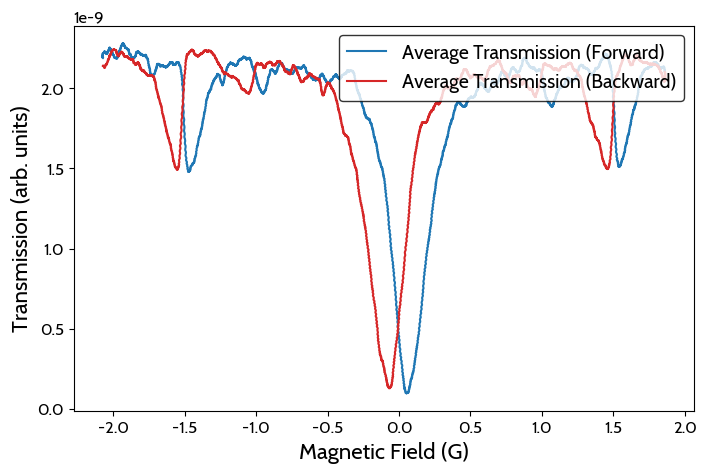

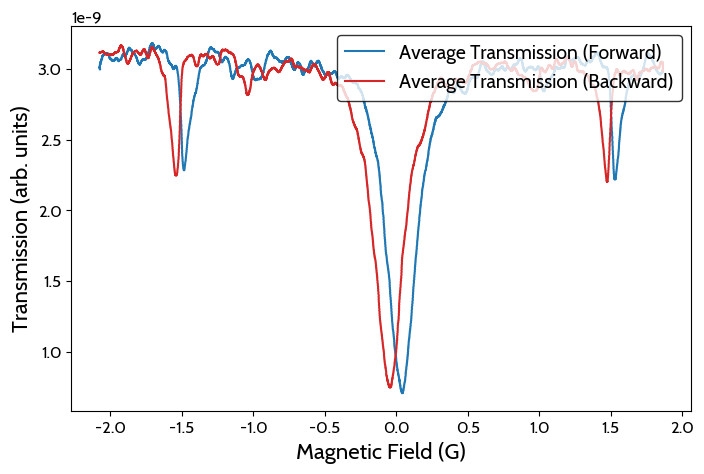

In [5]:
f500, fs500, b500, bs500 = speed_test(500, range(100, 108), True)
f400, fs400, b400, bs400 = speed_test(400, range(124, 132), True)
f300, fs300, b300, bs300 = speed_test(300, range(59, 67), True)
f200, fs200, b200, bs200 = speed_test(200, range(68, 76), True)
f100, fs100, b100, bs100 = speed_test(100, range(76, 84), True)
f150, fs150, b150, bs150 = speed_test(150, range(84, 92), False)
f250, fs250, b250, bs250 = speed_test(250, range(92, 100), False)

(array([0.00035669, 0.00071309]),
 array([1.01042888e-05, 3.04329268e-03]),
 array([-0.00031457, -0.02168032]),
 array([1.71768186e-05, 5.17345378e-03]))

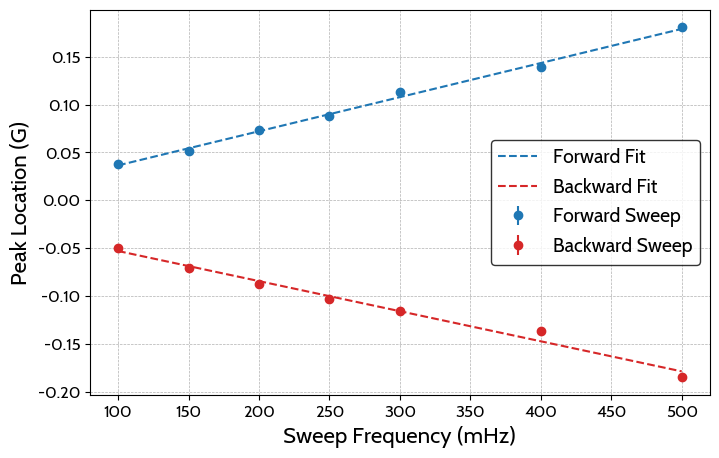

In [6]:
sweep_frequencies = np.array([100, 150, 200, 250, 300, 400, 500])
forward_centers = np.array([f100, f150, f200, f250, f300, f400, f500])
forward_centers_sigma = np.array([fs100, fs150, fs200, fs250, fs300, fs400, fs500])
backward_centers = np.array([b100, b150, b200, b250, b300, b400, b500])
backward_centers_sigma = np.array([bs100, bs150, bs200, bs250, bs300, bs400, bs500])

def linear(x, m, b):
    return m*x + b

popt1, pcov1 = curve_fit(linear, sweep_frequencies, forward_centers)
popt2, pcov2 = curve_fit(linear, sweep_frequencies, backward_centers)

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(sweep_frequencies, forward_centers, yerr=forward_centers_sigma, fmt='o', label='Forward Sweep', color='tab:blue')
ax.errorbar(sweep_frequencies, backward_centers, yerr=backward_centers_sigma, fmt='o', label='Backward Sweep', color='tab:red')

ax.plot(sweep_frequencies, linear(sweep_frequencies, *popt1), label=f'Forward Fit', color='tab:blue', linestyle='--')
ax.plot(sweep_frequencies, linear(sweep_frequencies, *popt2), label=f'Backward Fit', color='tab:red', linestyle='--')

ax.set_xlabel('Sweep Frequency (mHz)')
ax.set_ylabel('Peak Location (G)')
ax.legend()
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

popt1, np.sqrt(np.diag(pcov1)), popt2, np.sqrt(np.diag(pcov2))

[-8.00836421e-10 -1.47486569e+00  3.53721446e-02  3.09431094e-09]
[-9.09818032e-10 -1.54810027e+00 -3.32719008e-02  3.11662295e-09]
[-8.54769572e-10  1.53889375e+00  3.24259578e-02  3.05431906e-09]
[-8.13507792e-10  1.46685236e+00 -3.22263967e-02  3.01943654e-09]
[-7.82163229e-10 -1.46493903e+00  4.31033147e-02  2.60176277e-09]
[-7.36871519e-10 -1.56490953e+00  5.50429119e-02  2.59198898e-09]
[-6.38410558e-10  1.56028073e+00 -4.73326285e-02  2.51067500e-09]
[-7.33635870e-10  1.45256667e+00  5.09210153e-02  2.51684111e-09]
[-7.25692929e-10 -1.43935962e+00  6.52544195e-02  2.19673131e-09]
[-7.04055553e-10 -1.58043118e+00  5.60987035e-02  2.18839461e-09]
[-6.52184132e-10  1.56553190e+00 -4.76105650e-02  2.13115314e-09]
[-6.87788244e-10  1.42606679e+00  7.16834592e-02  2.18440033e-09]
[-7.00180558e-10 -1.42979418e+00  7.81317343e-02  3.92701191e-09]
[-5.92544125e-10 -1.58891502e+00  5.54898711e-02  3.86510463e-09]
[-6.27583932e-10  1.57995724e+00  6.41391114e-02  3.87640296e-09]
[-6.728236

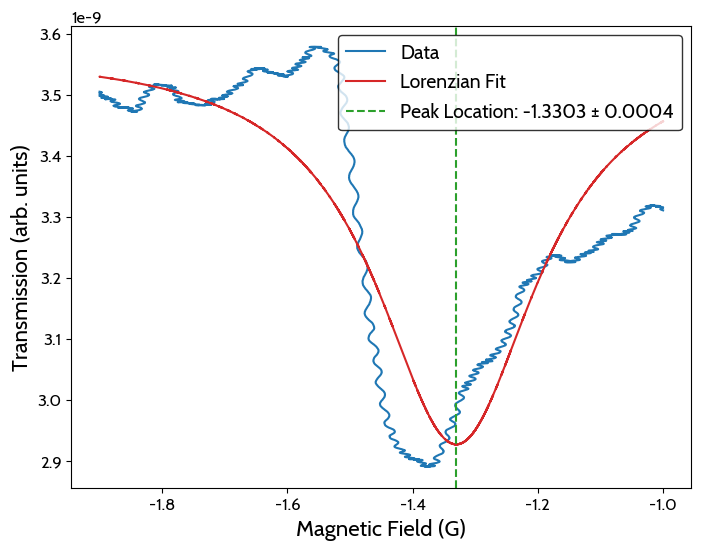

[-6.17769603e-10 -1.70149613e+00  1.83434057e-01  3.50303110e-09]


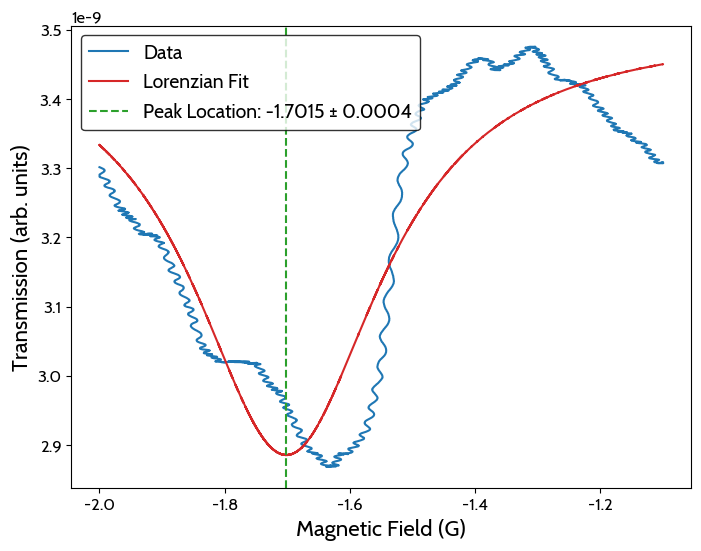

[-5.55773751e-10  1.66221900e+00  1.04716477e-01  3.33149037e-09]


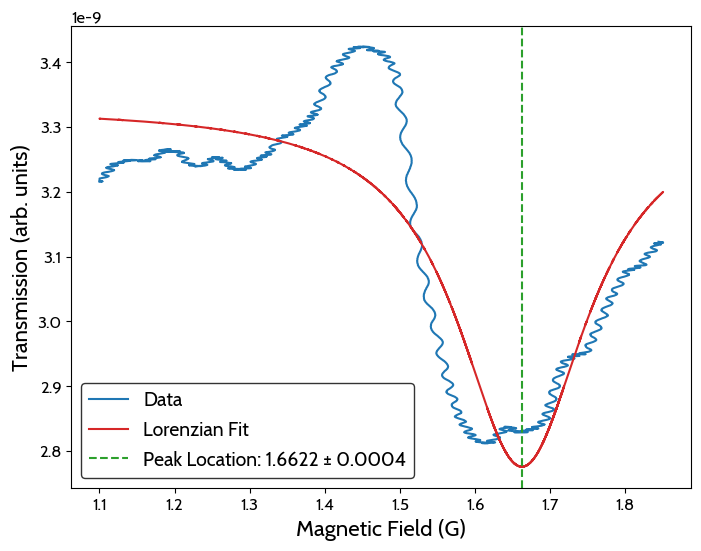

[-4.78710799e-10  1.36733233e+00  8.47694247e-02  3.32868222e-09]


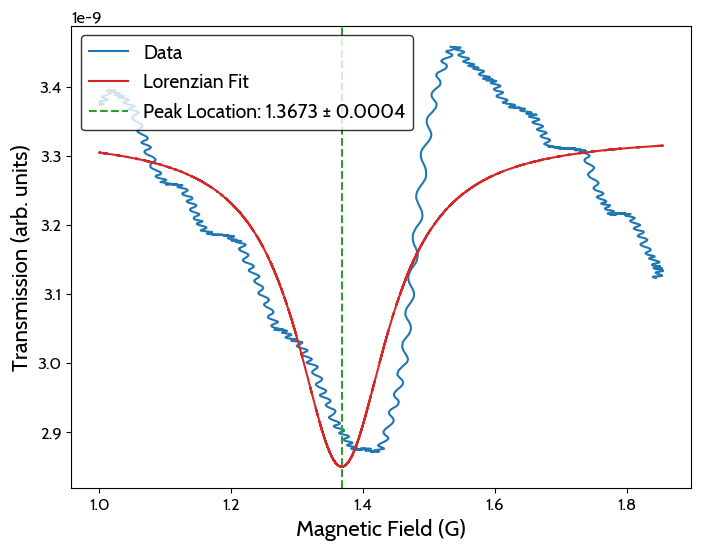

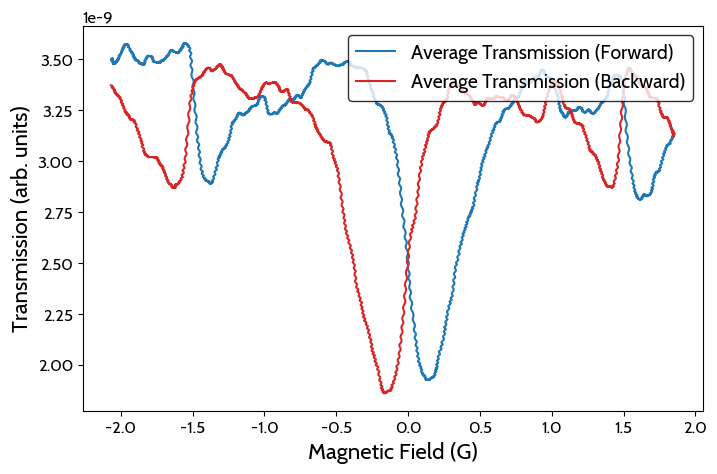

In [ ]:
f100, fs100, f100b, fs100b = speed_test_sides(100, range(76, 84), False)
f150, fs150, f150b, fs150b = speed_test_sides(150, range(84, 92), False)
f200, fs200, f200b, fs200b = speed_test_sides(200, range(68, 76), False)
f250, fs250, f250b, fs250b = speed_test_sides(250, range(92, 100), False)
f300, fs300, f300b, fs300b = speed_test_sides(300, range(59, 67), False)
f400, fs400, f400b, fs400b = speed_test_sides(400, range(124, 132), False)
f500, fs500, f500b, fs500b = speed_test_sides(500, range(100, 108), True)

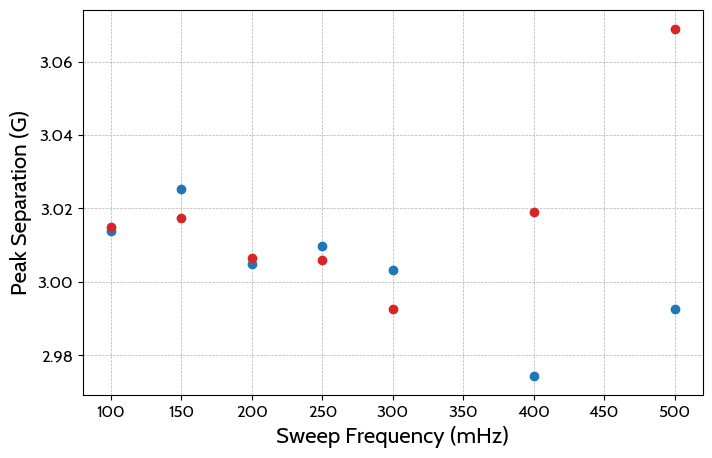

In [ ]:
sweep_frequencies = np.array([100, 150, 200, 250, 300, 400, 500])
forward_differences = np.array([f100, f150, f200, f250, f300, f400, f500])
forward_differences_sigma = np.array([fs100, fs150, fs200, fs250, fs300, fs400, fs500])
backward_differences = np.array([f100b, f150b, f200b, f250b, f300b, f400b, f500b])
backward_differences_sigma = np.array([fs100b, fs150b, fs200b, fs250b, fs300b, fs400b, fs500b])

fig, ax = plt.subplots(figsize=(8, 5))
ax.errorbar(sweep_frequencies, forward_differences, yerr=forward_differences_sigma, fmt='o', label='Forward Sweep', color='tab:blue')
ax.errorbar(sweep_frequencies, backward_differences, yerr=backward_differences_sigma, fmt='o', label='Backward Sweep', color='tab:red')
ax.set_xlabel('Sweep Frequency (mHz)')
ax.set_ylabel('Peak Separation (G)')
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# long test

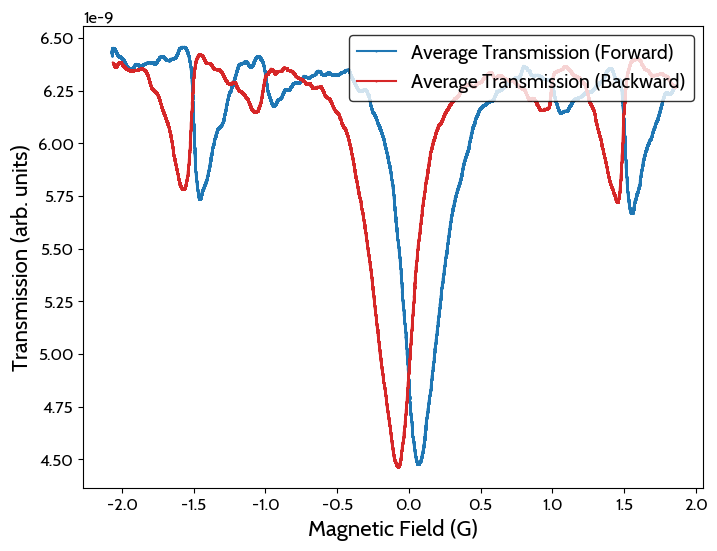

In [ ]:
plot_average(250, range(132, 152), "24", "long_test")

# powers

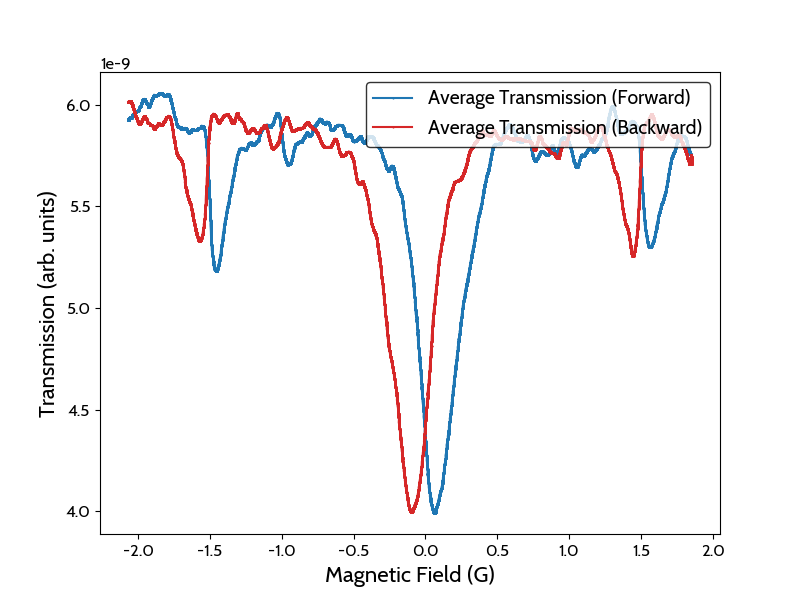

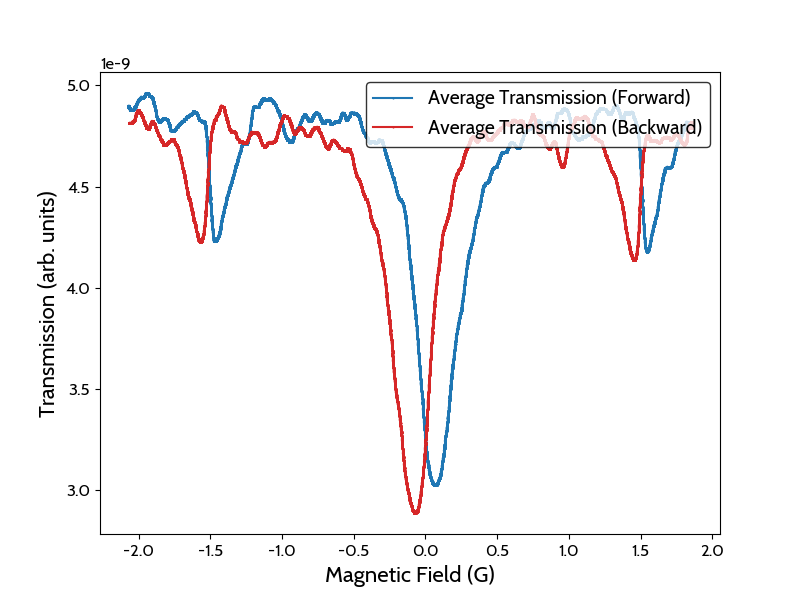

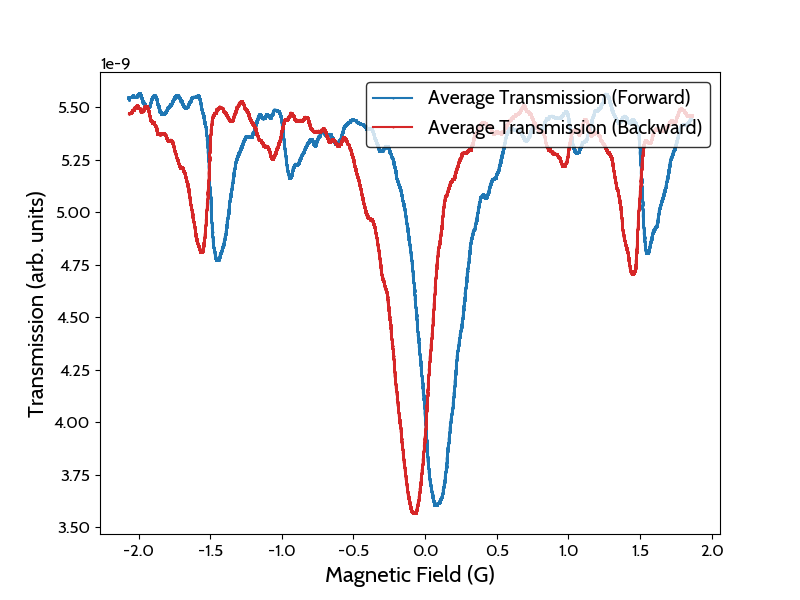

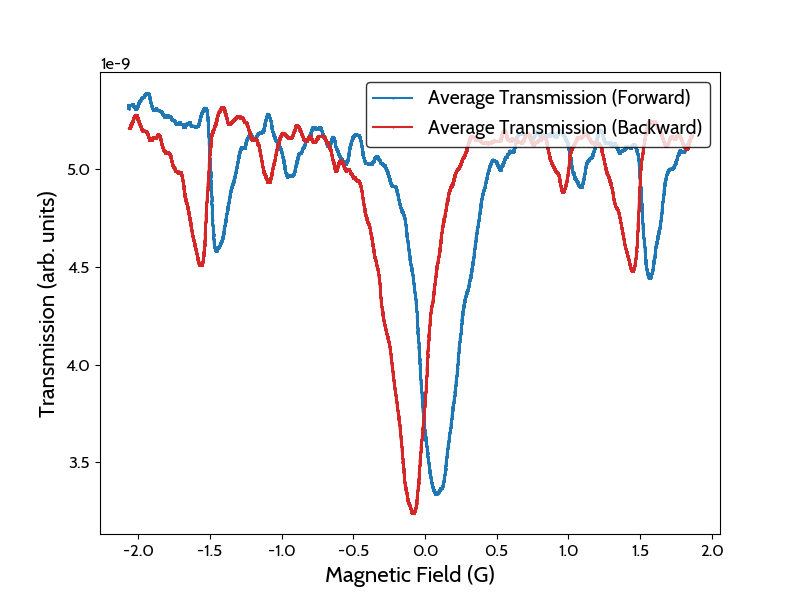

In [ ]:
plot_average(250, range(152, 159), "24", "power_3vpp")
plot_average(250, range(176, 184), "24", "power_4vpp")
plot_average(250, range(160, 168), "24", "power_5vpp")
plot_average(250, range(168, 174), "24", "power_6vpp")